In [20]:
from qiskit import *
from qiskit_algorithms import Grover
%matplotlib inline
from qiskit.circuit.library import PhaseOracle

In [21]:
#Dinner party example
logicalexpressions = '((James & Lars) | (Kirk & Rob)) &~ (Lars & Rob)' 

In [40]:
oracle = PhaseOracle(logicalexpressions)

/var/folders/kf/jd5w__vs3kg4vxwlhcczgzsm0000gn/T/ipykernel_43223/3740030205.py:1: DeprecationWarning: The class ``qiskit.circuit.library.phase_oracle.PhaseOracle`` is deprecated as of Qiskit 2.2. It will be removed in Qiskit 3.0. Use the class qiskit.circuit.library.PhaseOracleGate instead.
  oracle = PhaseOracle(logicalexpressions)


In [41]:
from qiskit.circuit.library import GroverOperator

grover_operator = GroverOperator(oracle)

/var/folders/kf/jd5w__vs3kg4vxwlhcczgzsm0000gn/T/ipykernel_43223/177594489.py:3: DeprecationWarning: The class ``qiskit.circuit.library.grover_operator.GroverOperator`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use qiskit.circuit.library.grover_operator instead.
  grover_operator = GroverOperator(oracle)


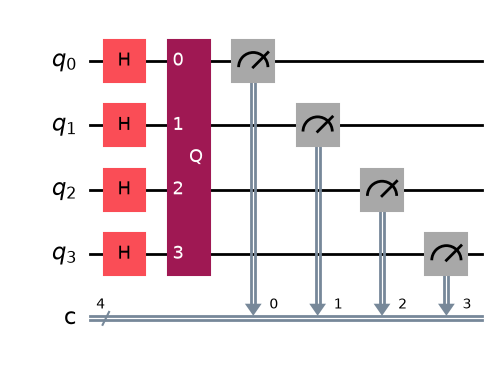

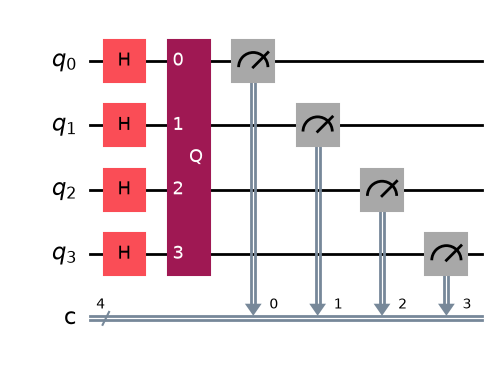

In [42]:
n = oracle.num_qubits

circuit = QuantumCircuit(n, n)

circuit.h(range(n))

circuit.compose(grover_operator, inplace=True)

circuit.measure(range(n), range(n))

circuit.draw('mpl')

In [44]:
from qiskit_aer import AerSimulator
from qiskit import transpile

simulator = AerSimulator()

# Convert the circuit into instructions supported by Aer
compiled_circuit = transpile(circuit, simulator)

job = simulator.run(compiled_circuit, shots=1024)

result = job.result()

counts = result.get_counts()

print(counts)

{'0111': 252, '1100': 254, '1101': 235, '0011': 283}


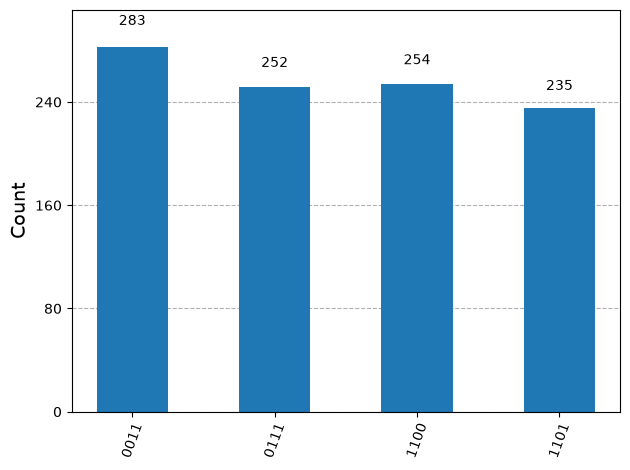

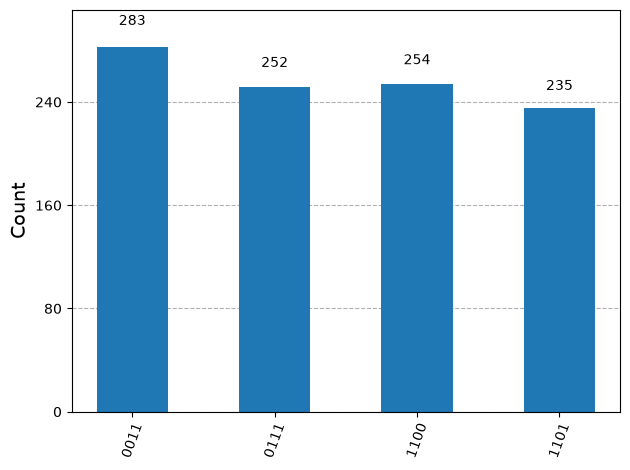

In [45]:
from qiskit.visualization import plot_histogram

plot_histogram(counts)